# Preparação Inicial

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import scipy.stats as stats
from sklearn.linear_model import LinearRegression
import warnings
import statsmodels.formula.api as smf

In [ ]:
df = pd.read_csv('ConcPatog.txt', sep='\t')
df.columns = df.columns.str.strip()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df.to_csv('ConcPatog_exportado.csv', index=False, sep=';', encoding='utf-8')

In [ ]:
# verificando nulos
print(df.isnull().sum())
print(f"CPatog1 iguais a zero: {(df['CPatog1'] == 0).sum()}")
print(f"CPatog2 iguais a zero: {(df['CPatog2'] == 0).sum()}")

ETE           0
Tratamento    0
Estagio       0
Mes           0
EstacaoAno    0
Amostra       0
CPatog1       0
CPatog2       0
PercRecup     0
dtype: int64
CPatog1 iguais a zero: 3
CPatog2 iguais a zero: 0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ETE         105 non-null    object 
 1   Tratamento  105 non-null    object 
 2   Estagio     105 non-null    int64  
 3   Mes         105 non-null    object 
 4   EstacaoAno  105 non-null    object 
 5   Amostra     105 non-null    int64  
 6   CPatog1     105 non-null    int64  
 7   CPatog2     105 non-null    int64  
 8   PercRecup   105 non-null    float64
dtypes: float64(1), int64(4), object(4)
memory usage: 7.5+ KB


In [ ]:
df.head()

,ETE,Tratamento,Estagio,Mes,EstacaoAno,Amostra,CPatog1,CPatog2,PercRecup
0,WWTP-1,1.Bruto,1,Abril,Seca,1,5210,7272,93.88
1,WWTP-1,1.Bruto,1,Maio,Seca,2,5770,12800,0.00
2,WWTP-1,1.Bruto,1,Junho,Seca,3,10700,179000,0.05
3,WWTP-1,1.Bruto,1,Julho,Seca,4,16700,190000,0.00
4,WWTP-1,1.Bruto,1,Agosto,Seca,5,5610,82875,39.11


## Entendimento das Variáveis do Dataset

O dataset `ConcPatog.txt` apresenta informações sobre as concentrações de dois tipos de protozoários em águas de esgoto, coletadas em diferentes condições. As variáveis disponíveis são:

*   **ETE (Categórica):** Identificação da Estação de Tratamento de Esgoto (WWTP-1, WWTP-2, WWTP-3).
*   **Tratamento (Categórica):** Estágio do tratamento no qual a amostra foi coletada (1. Bruto, 2. Secundário, 3. Reuso).
*   **Estagio (Numérica Discreta):** Representação numérica do estágio de tratamento (1, 2, 3).
*   **Mes (Categórica):** Mês da coleta da amostra.
*   **EstacaoAno (Categórica):** Estação do ano em que a coleta ocorreu (Seca ou Chuvosa).
*   **Amostra (Numérica Discreta):** Identificador único da amostra coletada.
*   **CPatog1 (Numérica Contínua - Variável Preditora/Independente - X):** Concentração medida do patógeno 1.
*   **CPatog2 (Numérica Contínua - Variável Resposta/Dependente - Y):** Concentração medida do patógeno 2.
*   **PercRecup (Numérica Contínua):** Percentual de recuperação, provavelmente associado à eficiência do método de detecção do patógeno.

O foco principal desta análise, conforme estabelecido no objetivo do trabalho, é investigar a relação linear para estimar a concentração do Patógeno 2 a partir do Patógeno 1.

# Preparação e Análise Exploratória


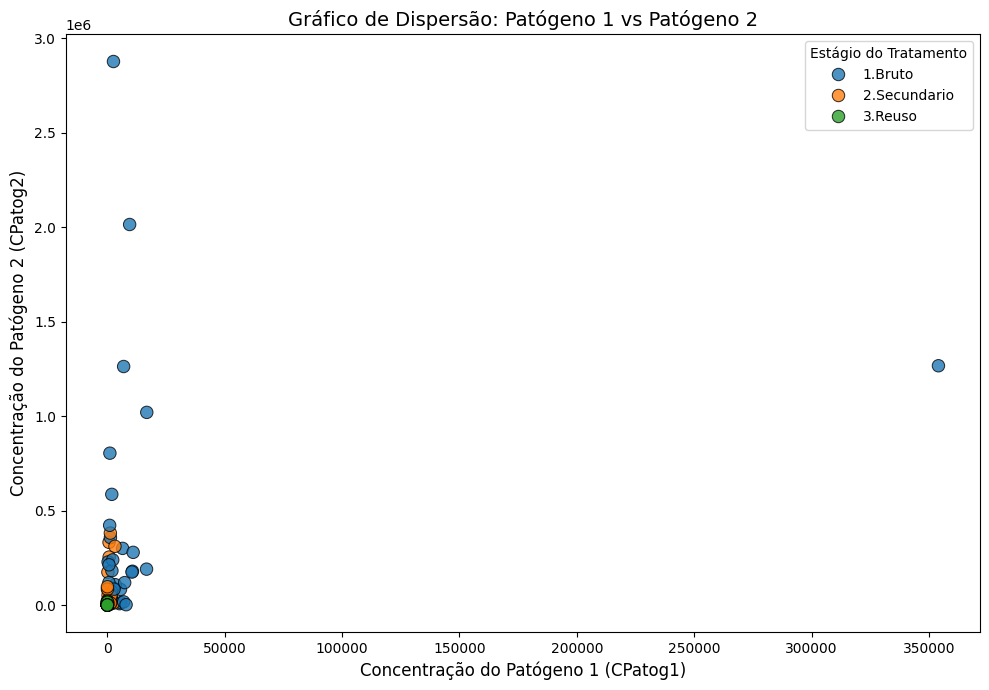

In [ ]:
# Disperação inicial:

plt.figure(figsize=(10, 7))

# gráfico de dispersão com mapeamento da etapa de tratamento
sns.scatterplot(data=df, x='CPatog1', y='CPatog2', hue='Tratamento', s=80, edgecolor='black', alpha=0.8)

# títulos e eixos
plt.title('Gráfico de Dispersão: Patógeno 1 vs Patógeno 2', fontsize=14)
plt.xlabel('Concentração do Patógeno 1 (CPatog1)', fontsize=12)
plt.ylabel('Concentração do Patógeno 2 (CPatog2)', fontsize=12)
plt.legend(title='Estágio do Tratamento')

plt.tight_layout()
plt.show()

### Análise do Gráfico de Dispersão Inicial:
A partir do gráfico de dispersão gerado para os dados originais, não há indício visual claro de associação linear entre as variáveis. Isso se deve à alta concentração dos pontos no canto inferior esquerdo do gráfico, indicando que a maior parte das amostras possui baixas concentrações para ambos os patógenos.

Além disso, a dispersão ocorre em formato de "L" acompanhando os eixos. Existem outliers da etapa "Bruto" atingindo valores altíssimos no eixo Y enquanto o X permanece baixo, e um ponto isolado de X alto com Y mediano.

A variação dos dados muda drasticamente dependendo do estágio do tratamento. Assim, os estágios "secundário" e de "reuso" estão "espremidos" próximos a zero, enquanto a água bruta apresenta enorme variabilidade. Esse comportamento assimétrico justifica a necessidade futura de uma transformação de escala para buscar um ajuste linear adequado.

### Análises Extras

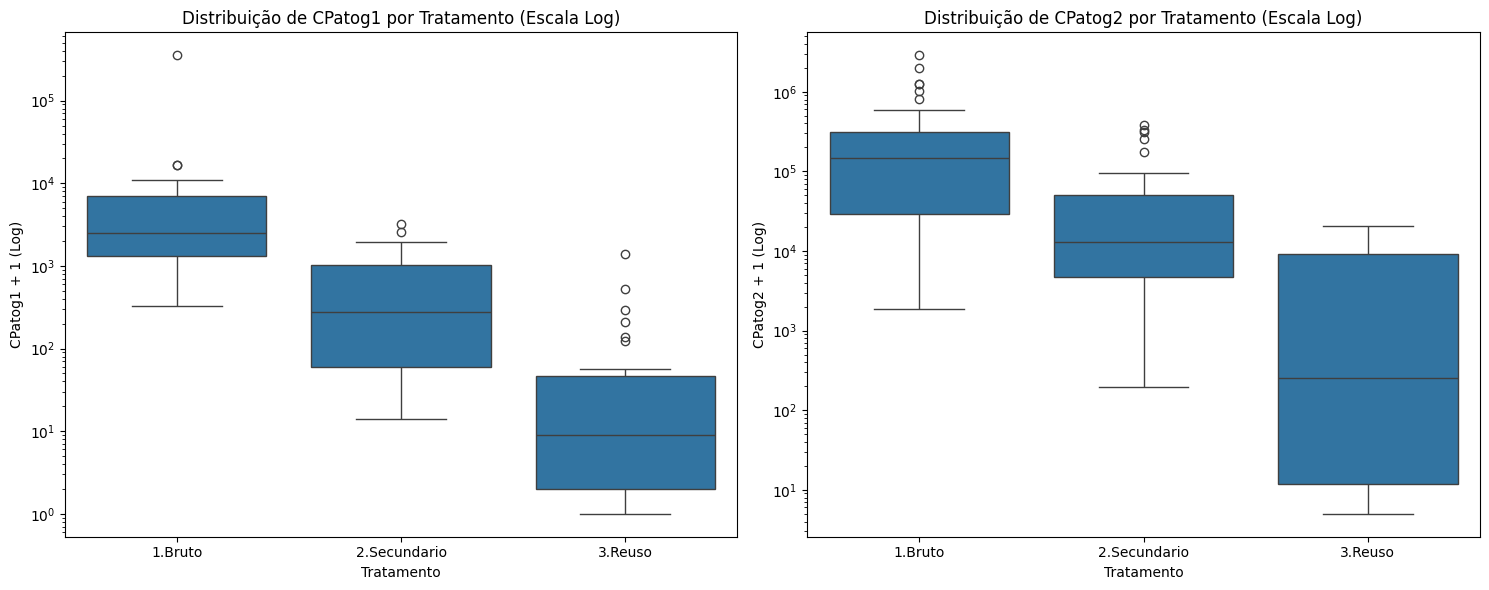

In [ ]:
# Análise Univariada e Boxplots

fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Adicionando uma constante pequena para evitar erro com log(0) no eixo
sns.boxplot(data=df, x='Tratamento', y=df['CPatog1'] + 1, ax=ax[0])
ax[0].set_yscale('log')
ax[0].set_title('Distribuição de CPatog1 por Tratamento (Escala Log)')
ax[0].set_ylabel('CPatog1 + 1 (Log)')

sns.boxplot(data=df, x='Tratamento', y=df['CPatog2'] + 1, ax=ax[1])
ax[1].set_yscale('log')
ax[1].set_title('Distribuição de CPatog2 por Tratamento (Escala Log)')
ax[1].set_ylabel('CPatog2 + 1 (Log)')

plt.tight_layout()
plt.show()

#### Dinâmica e Eficácia do Tratamento:

Observa-se uma queda progressiva nas concentrações medianas de ambos os patógenos à medida que o efluente avança pelos estágios do sistema. A carga biológica é altíssima na fase "1.Bruto", sofre uma redução acentuada no tratamento "2.Secundario" e atinge os seus níveis mais baixos na fase de "3.Reuso".

Este comportamento reflete a eficácia esperada das Estações de Tratamento de Esgoto (ETE) na remoção contínua dos microrganismos.

#### Elevada Dispersão e Outliers:

A fase "1.Bruto" não só apresenta as maiores concentrações, como também concentra a maior variabilidade dos dados e os outliers mais extremos (com o Patógeno 2 a ultrapassar a marca de $10^6$, ou seja, milhões). Como estes valores representam a condição natural e não tratada do esgoto, eles não são erros de medição, mas sim variações reais decorrentes de fatores externos (como o volume de chuvas).

#### Justificação para a Modelação na Escala Logarítmica:

O fato de ter sido estritamente necessário aplicar uma escala logarítmica no eixo Y para conseguir visualizar e comparar adequadamente as distribuições atesta que os dados variam em múltiplas ordens de magnitude. Na escala original (linear), esta expressiva diferença de amplitude entre o esgoto bruto e a água de reuso "esmaga" os valores baixos contra o eixo e amplifica os erros de predição. Portanto, esta visualização fornece a justificação empírica perfeita para a aplicação da transformação $Log_{10}(X+1)$ no modelo de regressão, sendo a única forma viável de estabilizar a variância (mitigar a heterocedasticidade) e capturar a relação entre os patógenos de forma fiável.

In [ ]:
# Filtrando as amostras com as concentrações mais extremas de Patógeno 2
limiar_outlier = df['CPatog2'].quantile(0.95) # Top 5% maiores valores
outliers_extremos = df[df['CPatog2'] > limiar_outlier].sort_values(by='CPatog2', ascending=False)

print(f"Limiar do percentil 95 para CPatog2: {limiar_outlier:.2f}")
display(outliers_extremos[['ETE', 'Tratamento', 'Mes', 'EstacaoAno', 'CPatog1', 'CPatog2']])

Limiar do percentil 95 para CPatog2: 760400.00


,ETE,Tratamento,Mes,EstacaoAno,CPatog1,CPatog2
7,WWTP-1,1.Bruto,Novembro,Chuvosa,2610,2877485
74,WWTP-3,1.Bruto,Setembro,Seca,9500,2014627
37,WWTP-2,1.Bruto,Agosto,Seca,354000,1266783
39,WWTP-2,1.Bruto,Outubro,Chuvosa,6940,1262809
72,WWTP-3,1.Bruto,Julho,Seca,16800,1020000
6,WWTP-1,1.Bruto,Outubro,Chuvosa,1090,804000


#### Inspeção dos Valores Extremos (Top 5%):

Ao estabelecermos um limiar no percentil 95 para a variável resposta (valores de CPatog2 acima de 760.400), isolamos os outliers mais "intensos" do nosso dataset. Assim, a inspeção direta revela um padrão unânime, isto é, todas essas amostras provêm exclusivamente da fase de tratamento "1.Bruto".

Esses picos ocorrem nas três diferentes estações (WWTP-1, WWTP-2 e WWTP-3) e em diferentes meses do ano. Desse modo, esses pontos não são necessariamente erros de medição ou anomalias do sensor, e, sim, representam o estado real e altamente variável do esgoto bruto antes de qualquer processamento. Como não se tratam de erros sistêmicos, remover esses outliers seria um erro metodológico grave. Essa reflexão reforça ainda mais a urgência de utilizar uma transformação de escala para a regressão, que consiga "puxar" esses valores reais e extremos para dentro de uma distribuição mais contida.

Como estes picos ocorrem de forma transversal nas três estações e em diferentes regimes climáticos, descarta-se a hipótese de se tratarem de anomalias pontuais do sensor ou erros de medição. Por serem dados legítimos do fenômeno, a eliminação destes outliers para tentar "forçar" um ajuste linear constituiria um grave erro metodológico. A abordagem correta, portanto, não é manipular a amostra, mas sim transformar a escala de medição, permitindo ao modelo acomodar estas grandes assimetrias de forma adequada.

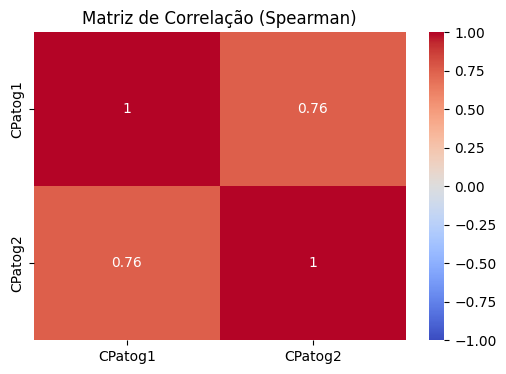

In [ ]:
# Calculando a correlação de Spearman
corr_spearman = df[['CPatog1', 'CPatog2']].corr(method='spearman')

plt.figure(figsize=(6, 4))
sns.heatmap(corr_spearman, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de Correlação (Spearman)')
plt.show()

#### Análise de Correlação Não-Paramétrica (Spearman):

Como diagnosticado no início da EDA, os dados originais não formam uma relação estritamente linear e sofrem forte influência de *outliers*. Aplicar a correlação de Pearson nesse cenário resultaria em um valor enviesado, pois ela pressupõe normalidade e linearidade.

Para contornar isso, utilizamos a correlação de Spearman, que é baseada nos ranks dos dados e avalia apenas a **relação monotônica**, ou seja, ela verifica se quando um patógeno cresce, o outro também tende a crescer, não importando se essa curva é linear, exponencial ou logarítmica.

O mapa de calor evidencia uma forte associação positiva e robusta entre o Patógeno 1 e o Patógeno 2. Assim, existe um sinal estatístico real e forte nos dados. Isso justifica matematicamente o próximo passo do estudo de encontrar a transformação de escala ideal que consiga linearizar essa relação monotônica detectada.

# Ajuste do Modelo, Intervalos e Resíduos

In [ ]:
# Preparação do modelo

X = df[['CPatog1']]
y = df['CPatog2']
n = len(y)
p = X.shape[1]

modelo_skl = LinearRegression()
modelo_skl.fit(X, y)

y_pred = modelo_skl.predict(X)
residuos = y - y_pred

# Cálculos estatísticos

r2 = modelo_skl.score(X, y)
r2_adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)
sqe = np.sum(residuos**2)
see = np.sqrt(sqe / (n - p - 1))

In [ ]:
# Ajuste do modelo linear simples usando statsmodels
# CPatog2 (Y) CPatog1 (X)
modelo_orig = smf.ols('CPatog2 ~ CPatog1', data=df).fit()

# Exibição do resumo completo na tabela OLS
print(modelo_orig.summary())

# Extração dos coeficientes para a equação da reta
b0_orig = modelo_orig.params['Intercept']
b1_orig = modelo_orig.params['CPatog1']

print(f"\nEquação da reta de regressão (Original):")
print(f"CPatog2 = {b0_orig:.4f} + {b1_orig:.4f} * CPatog1")

                            OLS Regression Results                            
Dep. Variable:                CPatog2   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.086
Method:                 Least Squares   F-statistic:                     10.81
Date:                Mon, 19 Oct 2026   Prob (F-statistic):            0.00138
Time:                        23:45:19   Log-Likelihood:                -1497.3
No. Observations:                 105   AIC:                             2999.
Df Residuals:                     103   BIC:                             3004.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1.315e+05   3.76e+04      3.497      0.0

Conforme a tabela de resultados do modelo OLS, o valor do $R^2$ ajustado é de 0.086 (ou 8,6%). Com base neste indicador, não é possível afirmar que o modelo captura bem a variabilidade da variável resposta. Muito embora, o modelo demonstra uma capacidade explicativa estatisticamente muito fraca. Isso significa que apenas 8,6% da variabilidade observada na concentração do Patógeno 2 (Y) consegue ser explicada pela variação linear da concentração do Patógeno 1 (X).

Os quase 91,4% restantes da variabilidade ficam no resíduo. Por isso, o baixo desempenho matemático é um reflexo direto do que foi diagnosticado na análise gráfica. No caso, a relação entre as variáveis na escala bruta não obedece a uma função linear simples e a reta é severamente distorcida pelos valores outliers presentes no esgoto bruto.

A própria tabela de regressão já nos dá indícios da violação da premissa de normalidade ao considerar que o teste de Jarque-Bera (JB) apresenta um p-value de 0.000 (Prob(JB)), e os valores de Skew (Assimetria = 5.147) e Kurtosis (Curtose = 32.866) estão muito distantes dos esperados para uma distribuição normal.

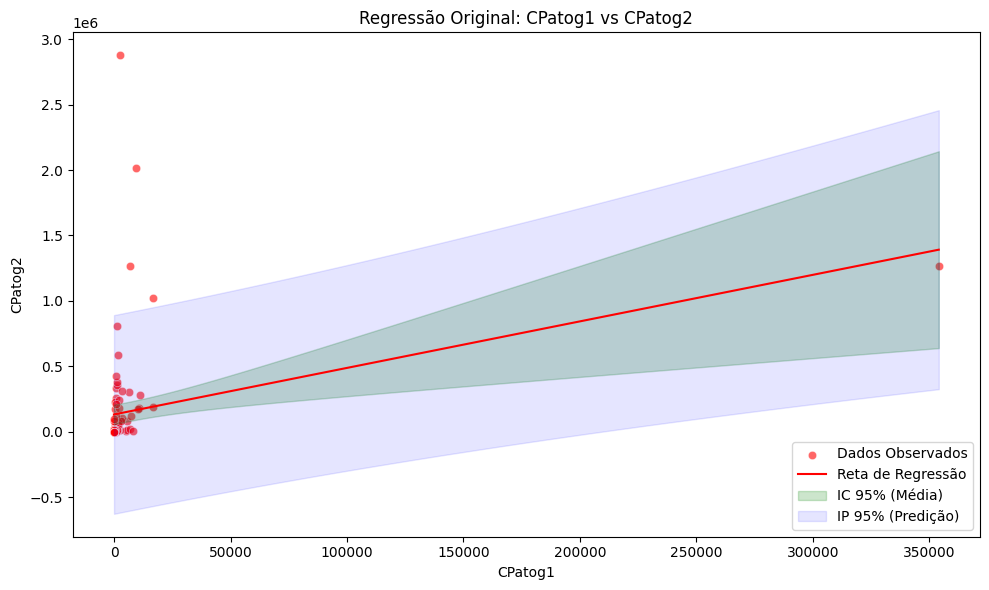

In [ ]:
# Cálculo das faixas de intervalo

gl = n - p - 1
t_crit = stats.t.ppf(0.975, gl) # Valor t para 95% de confiança

X_plot = np.linspace(X['CPatog1'].min(), X['CPatog1'].max(), 100)

X_plot_df = pd.DataFrame(X_plot, columns=['CPatog1'])
y_plot_pred = modelo_skl.predict(X_plot_df)

X_mean = np.mean(X['CPatog1'])
SXX = np.sum((X['CPatog1'] - X_mean)**2)

# Fórmulas do IC e IP
erro_ic = t_crit * see * np.sqrt((1/n) + ((X_plot - X_mean)**2 / SXX))
erro_ip = t_crit * see * np.sqrt(1 + (1/n) + ((X_plot - X_mean)**2 / SXX))

# Plotagem da Reta com IC e IP
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['CPatog1'], y=df['CPatog2'], color='red', alpha=0.6, label='Dados Observados')
plt.plot(X_plot, y_plot_pred, color='red', label='Reta de Regressão')
plt.fill_between(X_plot, y_plot_pred - erro_ic, y_plot_pred + erro_ic, color='green', alpha=0.2, label='IC 95% (Média)')
plt.fill_between(X_plot, y_plot_pred - erro_ip, y_plot_pred + erro_ip, color='blue', alpha=0.1, label='IP 95% (Predição)')
plt.title('Regressão Original: CPatog1 vs CPatog2')
plt.xlabel('CPatog1')
plt.ylabel('CPatog2')
plt.legend()
plt.tight_layout()
plt.show()

A visualização da reta de regressão com os respectivos intervalos aponta a ineficácia do modelo. A presença de *outliers* extremos com valores muito elevados de CPatog2 (Y) "puxa" a reta para cima e aumenta desproporcionalmente as faixas de erro. Observa-se que a maioria dos pontos está concentrada no canto inferior esquerdo, fora da zona central de predição ideal, e que o Intervalo de Predição (IP) é excessivamente largo, chegando a abranger valores negativos no eixo Y, o que não tem significado biológico para uma concentração.

## Gráficos de Resíduos

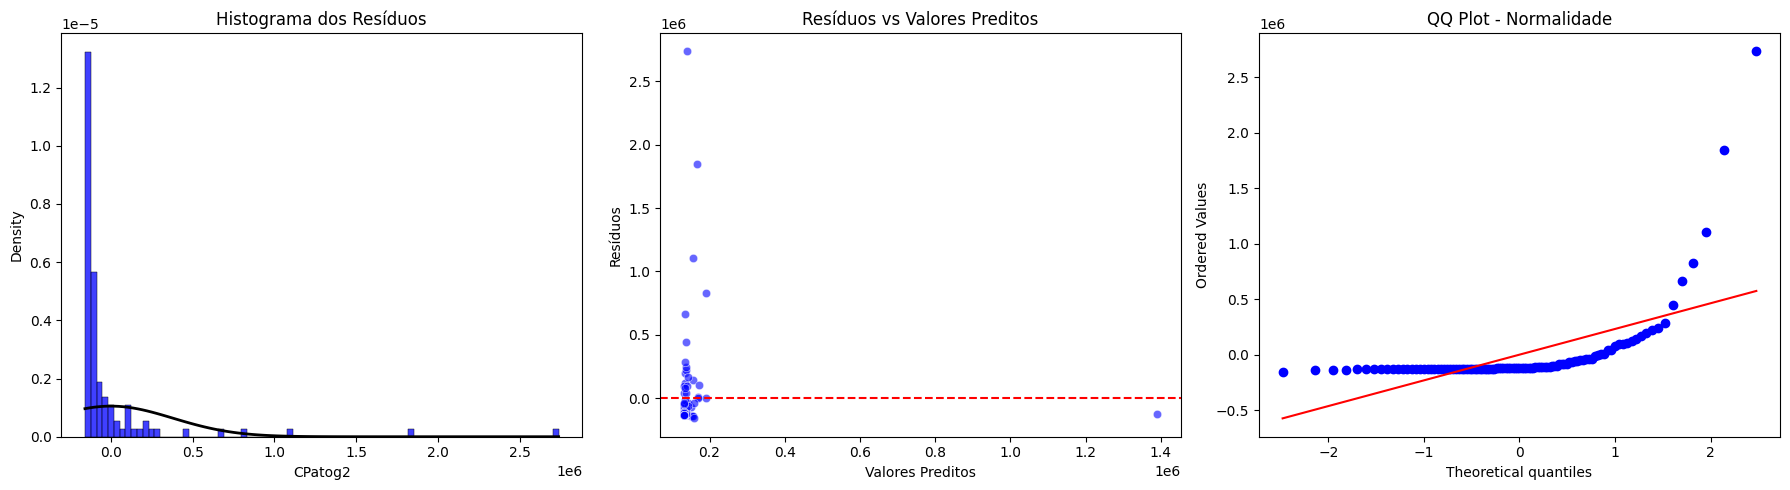

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Histograma
sns.histplot(residuos, stat='density', ax=ax[0], color='blue')
x_ext = np.linspace(residuos.min(), residuos.max(), 100)
ax[0].plot(x_ext, stats.norm.pdf(x_ext, residuos.mean(), residuos.std()), color='black', lw=2)
ax[0].set_title('Histograma dos Resíduos')

# Resíduos vs Preditos
sns.scatterplot(x=y_pred, y=residuos, ax=ax[1], color='blue', alpha=0.6)
ax[1].axhline(0, color='red', linestyle='--')
ax[1].set_title('Resíduos vs Valores Preditos')
ax[1].set_xlabel('Valores Preditos')
ax[1].set_ylabel('Resíduos')

# QQ-Plot usando Scipy
stats.probplot(residuos, dist="norm", plot=ax[2])
ax[2].set_title('QQ Plot - Normalidade')

plt.tight_layout()
plt.show()

In [ ]:
# Teste de Normalidade (Shapiro-Wilk)
stat_sw, p_sw = stats.shapiro(residuos)
print("Testes Estatísticos dos Resíduos")
print(f"Shapiro-Wilk (Normalidade): p-value = {p_sw:.5e}")

Testes Estatísticos dos Resíduos
Shapiro-Wilk (Normalidade): p-value = 4.18435e-19


## Verificação das Premissas LINE (Diagnóstico de Resíduos):

A inspeção da trinca de gráficos de resíduos revela violações severas às premissas fundamentais da regressão linear:

* Normalidade: O valor de p-value do teste de Shapiro-Wilk deu 4.18435e-19, um valor infinitamente menor que 0.05, rejeitando a hipótese de normalidade. Isso é perfeitamente identificável na forma com que os pontos azuis do QQ-Plot fogem drasticamente da linha vermelha nas extremidades.

* Homocedasticidade: O gráfico central mostra um exemplo de um padrão em funil. À medida que o valor predito aumenta (eixo X), o erro/resíduo espalha-se muito mais (eixo Y).

* Linearidade: Devido à aglomeração massiva de dados próximos a zero e à presença de outliers extremos, a relação não segue uma tendência linear consistente.

# Exploração de Transformações

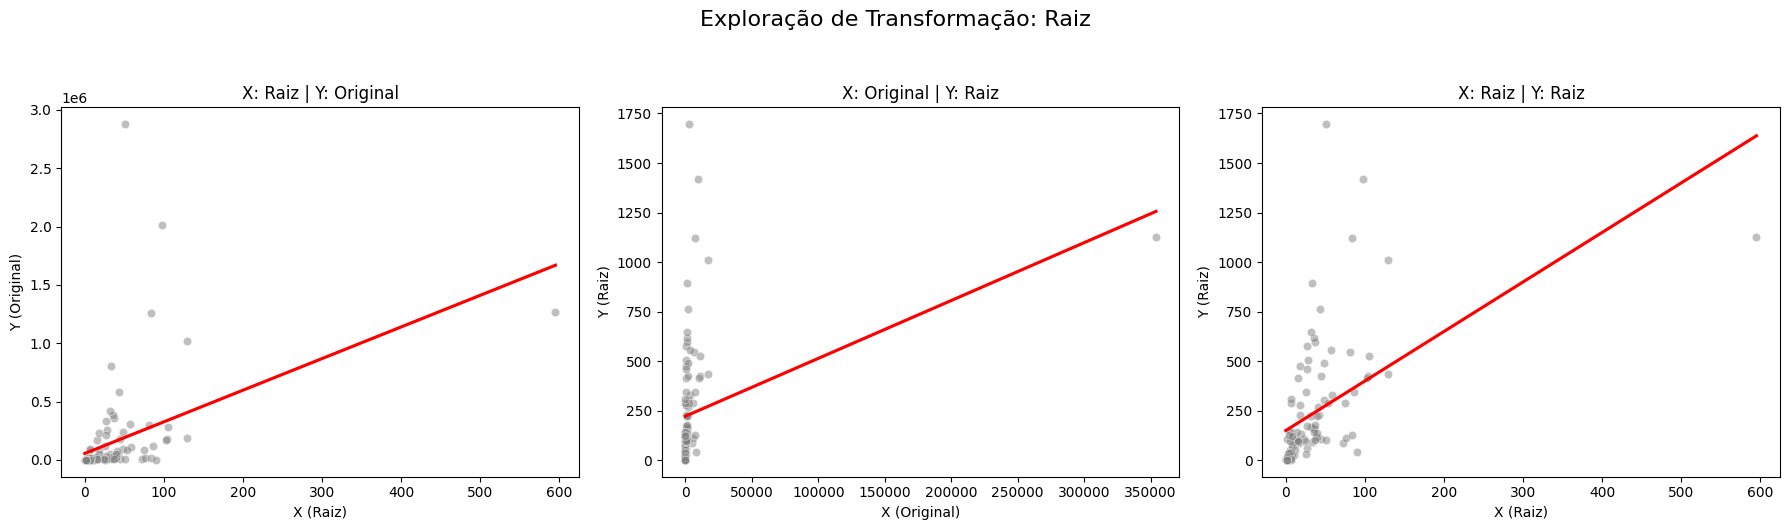

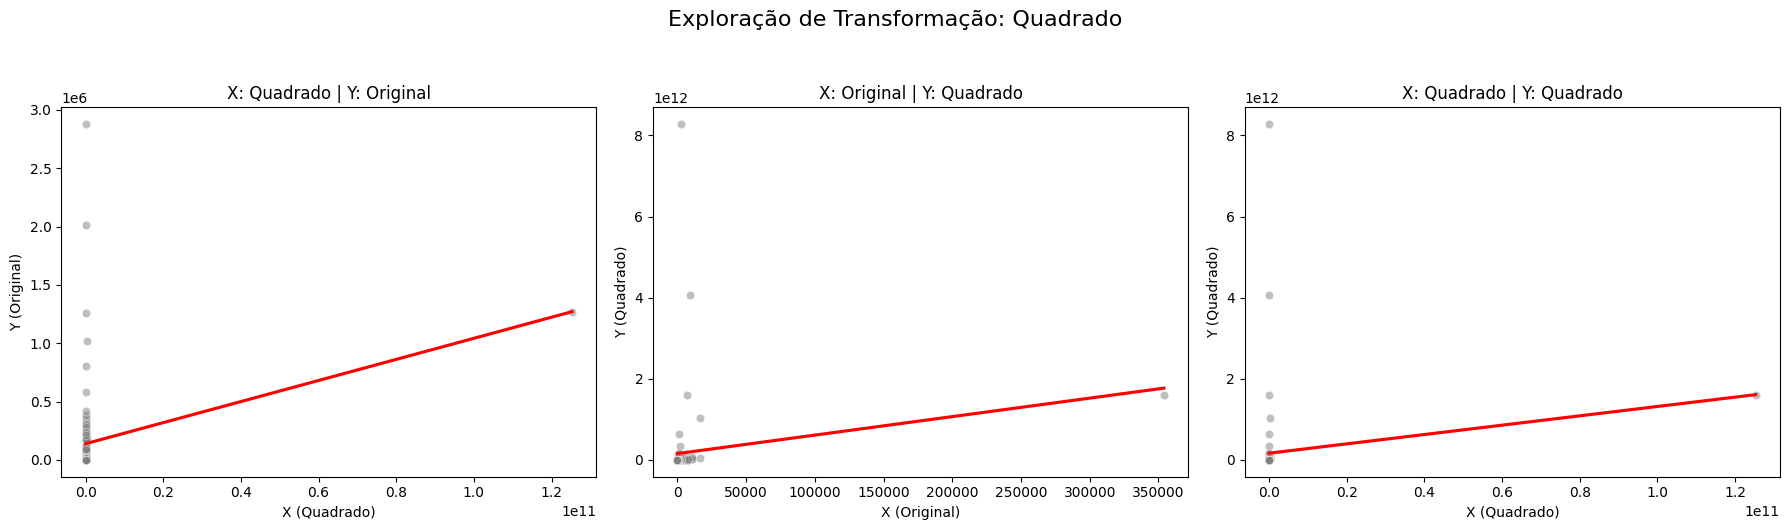

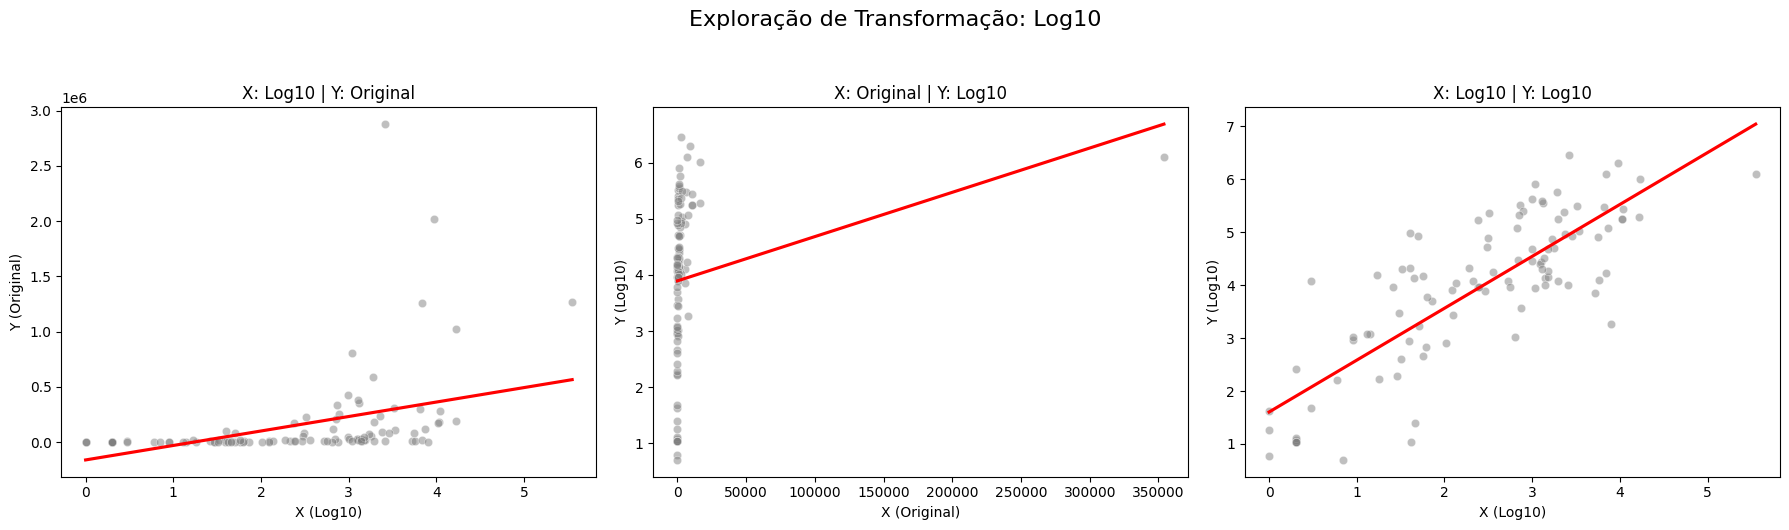

In [ ]:
warnings.filterwarnings('ignore')

# Dicionário apenas com as funções de transformação
transf_funcs = {
    'Raiz': np.sqrt,
    'Quadrado': np.square,
    'Log10': lambda x: np.log10(x + 1)
}

# Loop pelas 3 famílias de transformações (Raiz, Quadrado, Log10)
for nome_transf, func in transf_funcs.items():

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Exploração de Transformação: {nome_transf}', fontsize=16, y=1.05)

    # Valores originais
    X_orig = df['CPatog1']
    y_orig = df['CPatog2']

    # Valores transformados
    X_t = func(X_orig)
    y_t = func(y_orig)

    # Somente X transformado, Y original
    sns.scatterplot(x=X_t, y=y_orig, ax=axes[0], color='gray', alpha=0.5)
    sns.regplot(x=X_t, y=y_orig, ax=axes[0], scatter=False, color='red', ci=None)
    axes[0].set_title(f"X: {nome_transf} | Y: Original")
    axes[0].set_xlabel(f"X ({nome_transf})")
    axes[0].set_ylabel("Y (Original)")

    # X original, Somente Y transformado
    sns.scatterplot(x=X_orig, y=y_t, ax=axes[1], color='gray', alpha=0.5)
    sns.regplot(x=X_orig, y=y_t, ax=axes[1], scatter=False, color='red', ci=None)
    axes[1].set_title(f"X: Original | Y: {nome_transf}")
    axes[1].set_xlabel("X (Original)")
    axes[1].set_ylabel(f"Y ({nome_transf})")

    # Ambas as variáveis transformadas
    sns.scatterplot(x=X_t, y=y_t, ax=axes[2], color='gray', alpha=0.5)
    sns.regplot(x=X_t, y=y_t, ax=axes[2], scatter=False, color='red', ci=None)
    axes[2].set_title(f"X: {nome_transf} | Y: {nome_transf}")
    axes[2].set_xlabel(f"X ({nome_transf})")
    axes[2].set_ylabel(f"Y ({nome_transf})")

    plt.tight_layout()
    plt.show()

## Análise Visual das Transformações:

### O Efeito do Logaritmo:

A inspeção visual dos gráficos de dispersão é a etapa definitiva para validar a escolha da transformação adequada, cumprindo a diretriz de verificar a associação entre as variáveis. Ao analisar as transformações logarítmicas (a que apresentou melhor desempenho numérico anterior), o painel ilustra o impacto prático de cada abordagem na geometria dos dados:   
1. Transformação Unilateral (Apenas em X ou apenas em Y falham): Ao transformar apenas a variável preditora, o eixo X é comprimido e estabilizado, mas os outliers extremos da variável resposta (Y) continuam a dominar o gráfico nos valores mais intensos. Assim, a reta de regressão é quase plana, ignora a densidade principal da massa de dados e a severa heterocedasticidade permanece evidente. Ainda sim, ao transformar apenas a variável resposta, os dados agrupam-se numa linha vertical próxima de X=0 e o outlier extremo do eixo X (concentração > 350.000) atua como um ponto de leverage, "puxando" a reta de regressão para si e distorcendo.
2. Transformação Bilateral: Quando aplicamos a escala logarítmica simultaneamente a ambas as variáveis, o problema de escala é resolvido. Os pontos que antes estavam espremidos revelam uma clara associação linear positiva. Ademais, a reta de regressão corta exatamente o centro da nuvem de pontos, e a dispersão torna-se visivelmente mais constante e equilibrada ao longo de todo o eixo.

A verificação visual comprova de forma inquestionável o diagnóstico numérico de que a transformação $Log_{10}$ aplicada tanto em X quanto em Y é a melhor combinação testada para ajustar a relação biológica entre os patógenos, atenuar o peso desproporcional dos valores extremos originais e aproximar substancialmente o modelo do cumprimento das premissas LINE, garantindo especialmente a Linearidade e a Igualdade de Variância.

In [ ]:
warnings.filterwarnings('ignore')

# Dicionário com as funções matemáticas
transformacoes = {
    'Original': lambda x: x,
    'Raiz': np.sqrt,
    'Quadrado': np.square,
    'Log10': lambda x: np.log10(x + 1)
}

resultados_transf = []

# Loop iterando sobre todas as combinações possíveis para X e Y
for nome_x, func_x in transformacoes.items():
    for nome_y, func_y in transformacoes.items():
        if nome_x == 'Original' and nome_y == 'Original':
            continue

        # Aplica a transformação
        X_transf = func_x(X)
        y_transf = func_y(y)

        # Ajusta o modelo com Scikit-Learn
        modelo_t = LinearRegression()
        modelo_t.fit(X_transf, y_transf)

        # Calcula o R² Ajustado
        r2_t = modelo_t.score(X_transf, y_transf)
        r2_adj_t = 1 - (1 - r2_t) * (n - 1) / (n - p - 1)

        resultados_transf.append({
            'Transformação X': nome_x,
            'Transformação Y': nome_y,
            'R² Ajustado': r2_adj_t
        })

# Exibe o ranking final ordenado do melhor para o pior R²
df_resultados = pd.DataFrame(resultados_transf).sort_values(by='R² Ajustado', ascending=False)
display(df_resultados.head(9))

,Transformação X,Transformação Y,R² Ajustado
14,Log10,Log10,0.660122
12,Log10,Raiz,0.344600
4,Raiz,Raiz,0.256005
3,Raiz,Original,0.175907
6,Raiz,Log10,0.171162
11,Log10,Original,0.147510
0,Original,Raiz,0.099022
8,Quadrado,Raiz,0.072998
7,Quadrado,Original,0.067804


# Modelo Otimizado

In [ ]:
# Criando colunas transformadas no df
df['LogCPatog1'] = np.log10(df['CPatog1'] + 1)
df['LogCPatog2'] = np.log10(df['CPatog2'] + 1)

# Ajuste do modelo usando statsmodels para a escala otimizada
modelo_opt_sm = smf.ols('LogCPatog2 ~ LogCPatog1', data=df).fit()

# Exibição do resumo completo
print(modelo_opt_sm.summary())

# Extração dos coeficientes
b0_opt = modelo_opt_sm.params['Intercept']
b1_opt = modelo_opt_sm.params['LogCPatog1']

print(f"\nEquação da reta de regressão (Otimizada):")
print(f"LogCPatog2 = {b0_opt:.4f} + {b1_opt:.4f} * LogCPatog1")

                            OLS Regression Results                            
Dep. Variable:             LogCPatog2   R-squared:                       0.663
Model:                            OLS   Adj. R-squared:                  0.660
Method:                 Least Squares   F-statistic:                     203.0
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           4.25e-26
Time:                        23:46:09   Log-Likelihood:                -130.01
No. Observations:                 105   AIC:                             264.0
Df Residuals:                     103   BIC:                             269.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.6043      0.183      8.762      0.0

Para determinar a melhor forma de estabilizar a variância e ajustar a relação entre os patógenos, foram testadas diferentes combinações de transformações sobre as variáveis preditora (X) e resposta (Y). O critério objetivo de desempate foi o valor do $R^2$ Ajustado.

**Análise dos Resultados Exploratórios:**
* **A Combinação Ideal:** A aplicação da transformação **Log10 em ambas as variáveis** (X e Y) obteve, de longe, o melhor desempenho, atingindo um $R^2$ ajustado de **0.6601**. Este valor representa um aumento muito significativo na capacidade explicativa do modelo em relação aos dados brutos.
* **Desempenho Intermediário:** Transformações baseadas na Raiz Quadrada trouxeram melhorias parciais, mas não suficientes. A melhor combinação sem usar Log10 em ambas foi Log10 em X e Raiz em Y ($R^2$ de 0.3446), seguida por Raiz em ambas ($R^2$ de 0.2560).
* **Pior Desempenho:** A transformação ao Quadrado prejudicou a associação linear, gerando resultados piores que a escala original. A combinação de Quadrado em X e Original em Y obteve o menor R² da tabela, com apenas 0.0678.

**Conclusão da Exploração:**
Os testes numéricos indicam inequivocamente que a escala logarítmica é a mais apropriada para a natureza destes dados. Sendo assim, o modelo otimizado adotará a transformação **Log10 para X e Y**. Como verificado na Análise Exploratória, a coluna CPatog1 possui valores exatos a zero, logo, a operação matemática utilizada para evitar erros de cálculo (logaritmo indefinido) será **$log_{10}(X + 1)$** e **$log_{10}(Y + 1)$**.

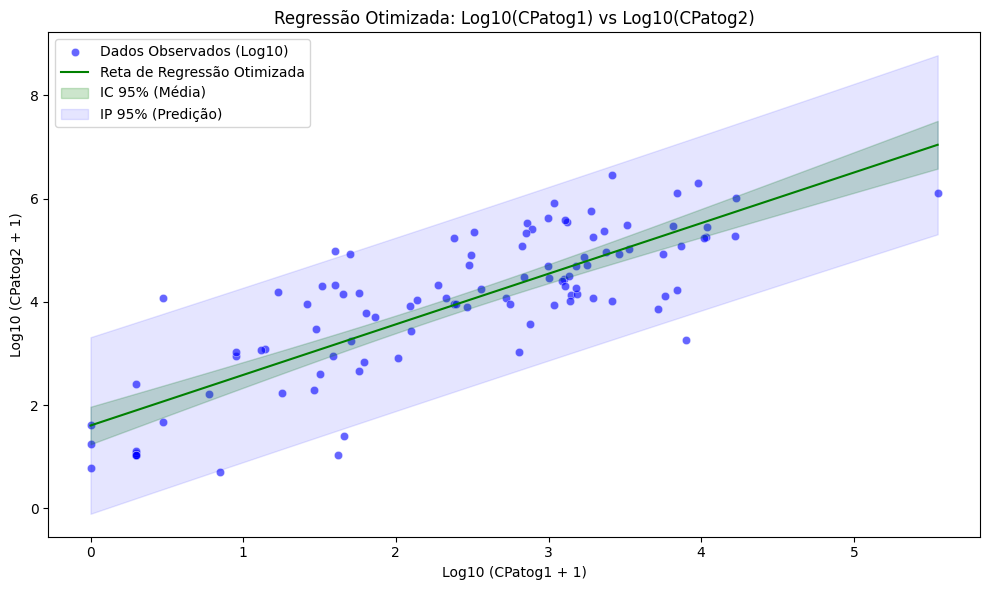

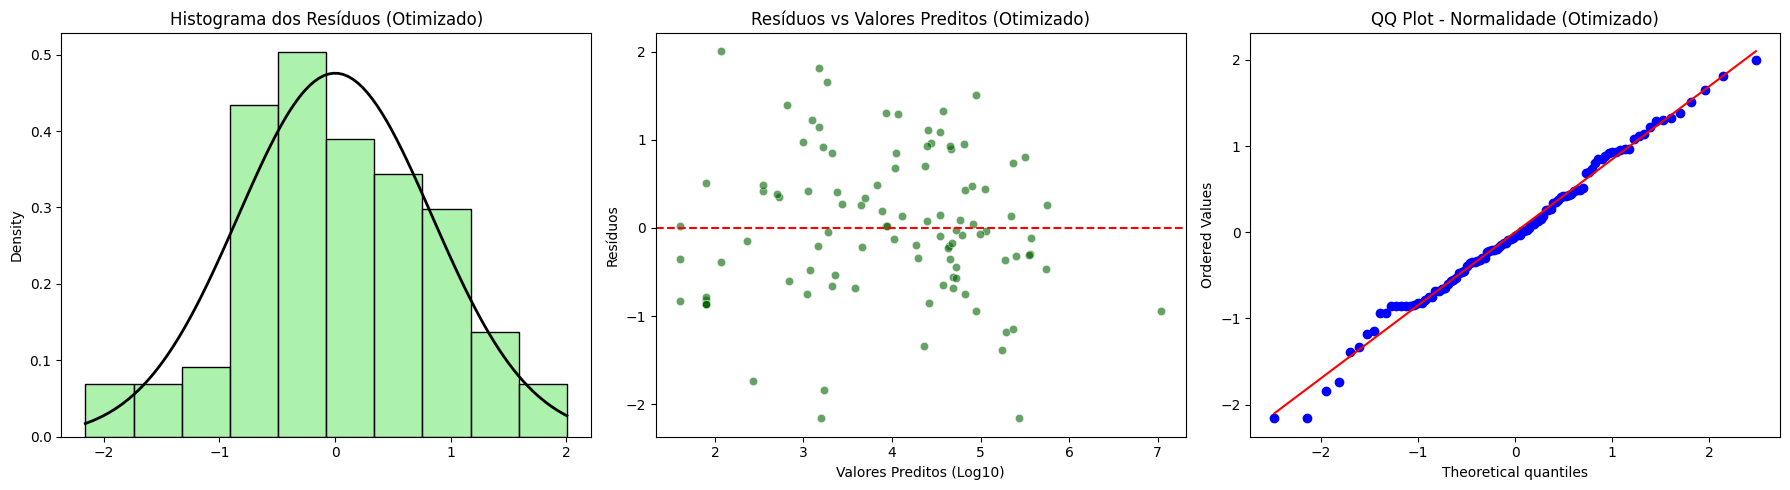

In [ ]:
# Definição e cálculos para as variáveis otimizadas (escala log10)
X_opt = df[['LogCPatog1']].rename(columns={'LogCPatog1': 'CPatog1'})
y_opt = df['LogCPatog2']
n_opt = len(y_opt)
p_opt = X_opt.shape[1]

# Resíduos e predições do modelo otimizado
y_pred_opt = modelo_opt_sm.predict(df['LogCPatog1'])
residuos_opt = y_opt - y_pred_opt

# Desvio padrão residual (SEE) do modelo otimizado
see_opt = np.sqrt(modelo_opt_sm.ssr / (n_opt - p_opt - 1))
gl_opt = n_opt - p_opt - 1
t_crit_opt = stats.t.ppf(0.975, gl_opt)

# Geração da grade para plotagem contínua
X_plot_opt = np.linspace(X_opt['CPatog1'].min(), X_opt['CPatog1'].max(), 100)
y_plot_pred_opt = b0_opt + b1_opt * X_plot_opt

# Cálculos de IC e IP
X_mean_opt = np.mean(X_opt['CPatog1'])
SXX_opt = np.sum((X_opt['CPatog1'] - X_mean_opt)**2)

erro_ic_opt = t_crit_opt * see_opt * np.sqrt((1 / n_opt) + ((X_plot_opt - X_mean_opt)**2 / SXX_opt))
erro_ip_opt = t_crit_opt * see_opt * np.sqrt(1 + (1 / n_opt) + ((X_plot_opt - X_mean_opt)**2 / SXX_opt))

# Plotagem da reta otimizada com IC e IP
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_opt['CPatog1'], y=y_opt, color='blue', alpha=0.6, label='Dados Observados (Log10)')
plt.plot(X_plot_opt, y_plot_pred_opt, color='green', label='Reta de Regressão Otimizada')
plt.fill_between(X_plot_opt, y_plot_pred_opt - erro_ic_opt, y_plot_pred_opt + erro_ic_opt, color='green', alpha=0.2, label='IC 95% (Média)')
plt.fill_between(X_plot_opt, y_plot_pred_opt - erro_ip_opt, y_plot_pred_opt + erro_ip_opt, color='blue', alpha=0.1, label='IP 95% (Predição)')
plt.title('Regressão Otimizada: Log10(CPatog1) vs Log10(CPatog2)')
plt.xlabel('Log10 (CPatog1 + 1)')
plt.ylabel('Log10 (CPatog2 + 1)')
plt.legend()
plt.tight_layout()
plt.show()

# Gráficos de resíduos
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(residuos_opt, stat='density', ax=ax[0], color='lightgreen')
x_ext_opt = np.linspace(residuos_opt.min(), residuos_opt.max(), 100)
ax[0].plot(x_ext_opt, stats.norm.pdf(x_ext_opt, residuos_opt.mean(), residuos_opt.std()), color='black', lw=2)
ax[0].set_title('Histograma dos Resíduos (Otimizado)')

sns.scatterplot(x=y_pred_opt, y=residuos_opt, ax=ax[1], color='darkgreen', alpha=0.6)
ax[1].axhline(0, color='red', linestyle='--')
ax[1].set_title('Resíduos vs Valores Preditos (Otimizado)')
ax[1].set_xlabel('Valores Preditos (Log10)')
ax[1].set_ylabel('Resíduos')

stats.probplot(residuos_opt, dist="norm", plot=ax[2])
ax[2].set_title('QQ Plot - Normalidade (Otimizado)')

plt.tight_layout()
plt.show()

In [ ]:
# Teste de normalidade final
stat_sw_opt, p_sw_opt = stats.shapiro(residuos_opt)
print("\n Testes Estatísticos dos Resíduos Otimizados")
print(f"Shapiro-Wilk (Normalidade): p-value = {p_sw_opt:.5e}")


 Testes Estatísticos dos Resíduos Otimizados
Shapiro-Wilk (Normalidade): p-value = 6.85084e-01


### Análise do Ajuste do Modelo Otimizado

**Análise do Gráfico da Reta (Escala Logarítmica):**
A aplicação da transformação $log_{10}$ produziu um gráfico de dispersão muito mais equilibrado. A reta de regressão otimizada (em verde) atravessa o centro da nuvem de pontos de forma muito mais consistente do que no modelo original. A amplitude do Intervalo de Confiança (IC) e do Intervalo de Predição (IP) tornou-se proporcional aos dados, englobando a grande maioria das observações dentro dos limites teóricos esperados.

**Reavaliação das Premissas LINE (Diagnóstico de Resíduos):**
O modelo transformado resolveu de forma notável as graves violações observadas na escala original:
* **Linearidade:** A nuvem de pontos na escala logarítmica demonstra um padrão de associação linear forte e coerente entre o Patógeno 1 e o Patógeno 2.
* **Variância Igual / Homocedasticidade:** O gráfico central de "Resíduos vs. Valores Preditos" deixou de exibir o formato em funil. Os pontos encontram-se dispersos de forma aleatória e uniforme em torno da linha horizontal do zero, o que atesta a estabilização da variância em todos os níveis de predição.
* **Normalidade:** O histograma dos resíduos formou uma curva em sino e o QQ-Plot exibe um excelente alinhamento dos dados com a reta teórica. Esta premissa foi confirmada formalmente através do teste estatístico de Shapiro-Wilk, que resultou num **p-value = 0.685**. Sendo $p > 0.05$, a hipótese de normalidade dos erros é validada estatisticamente.

**Conclusão Geral:**
A transformação de escala foi bem-sucedida. O $R^2$ ajustado saltou de 0.0862 do modelo original para **0.6601**, o que significa que o modelo explica agora cerca de 66% da variabilidade dos dados. Além do considerável ganho preditivo, o modelo cumpre agora as premissas estruturais LINE, tornando a regressão estatisticamente sólida para estimar a concentração do Patógeno 2 a partir do Patógeno 1 no esgoto tratado.